In [1]:
# =============================================================================
# Created By:     Kai Metzger
# Created School: Franz-Oberthuer-Schule Wuerzburg
# Created Email:  metzgerkai@franz-oberthuer-schule.de
# Created Date:   Mon Nov 01 21:02 UTC 2026
# Version:        1.1.0
# =============================================================================
"""The Module has been build for training the symbols dataset with the 
following datasets consisting of images + ground truth. Images have the base 
dimenstions of 640px x 480px in datasets 1-8 and then another 700 images with 
resolution 1920px x 1080px have been added to the datasets9+.
The files in the dataset <symbols> should be ordered in the following
manner starting with dataset10+:
- symbols      
  - # dataset e.g. datset10 the corresponding classes are stored in folders 0-3:
    #     classA/     = cross       361
    #     classB/     = circle      358
    #     classC/     = triangle    360
    #     classD/     = rectangle   361
"""

# =============================================================================
# Import
# =============================================================================
import cv2
import os
import numpy as np
from pathlib import Path
from keras import layers, models, utils, callbacks
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from keras.optimizers.schedules import ExponentialDecay
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import splitfolders

# Enable Nvidia GPUs by un-commenting this line 
os.environ['CUDA_VISIBLE_DEVICES'] = "0"
XLA_FLAGS="--xla_gpu_cuda_data_dir=/usr/"

# To get reproducable results with the same training setting random seed
SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

DEBUG = True

In [2]:
# =============================================================================
# Declare variables / dataset
# =============================================================================
# Change the following paths to your dataset path
home_dir = os.path.expanduser("~")

dataset = "1"                                            # CHANGE DATASET NUMBER

dataset_for_training = "dataset" + str(dataset)  
dataset_for_training_split = dataset_for_training + "-split70-15-15"
checkpoint_filepath = home_dir + "/ml_project/datasets/symbols/chpt/"
print(dataset_for_training)
print(checkpoint_filepath)

dataset1
/home/pi/ml_project/datasets/symbols/chpt/


In [3]:
# =============================================================================
# Split into 70% train, 15% val, 15% test on disk
# =============================================================================
source_dir = Path(dataset_for_training_split)
split_dir = source_dir.parent / f"{source_dir.name}"

if not split_dir.exists():
    splitfolders.ratio(
        input=str(dataset_for_training),
        output=str(split_dir),
        shuffle=True,
        seed=SEED,
        ratio=(0.70, 0.15, 0.15),
    )
else:
    print(f"Split folder already exists; skipping: {split_dir}")

Split folder already exists; skipping: dataset1-split70-15-15


In [4]:
# =============================================================================
# Dataset related
# =============================================================================
NUM_CLASSES = 4                                     # change for other datasets
                                                    # e.g. 3 for rock, paper, 
                                                    # scissors
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
IMG_CHANNELS = 3                                       # 1=:grayscale, 3=:color
INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)

# =============================================================================
# Hyperparameters
# =============================================================================
BATCH_SIZE = 32
EPOCHS = 300
LEARNING_RATE = 1e-3

# Set up an exponential decay learning rate schedule
LR_SCHEDULER = ExponentialDecay(
    initial_learning_rate=LEARNING_RATE,    # start with 0.001
    decay_steps=500,                        # how often to apply the decay
    decay_rate=0.96,                        # decay rate
    staircase=True                          # whether to apply the decay in steps
)
OPTIMIZER_BASE = keras.optimizers.Adam(learning_rate=LR_SCHEDULER)

LR_SCHEDULER_FINE = ExponentialDecay(
    initial_learning_rate=LEARNING_RATE/10, # start with 0.001
    decay_steps=500,                        # how often to apply the decay
    decay_rate=0.96,                        # decay rate
    staircase=True                          # whether to apply the decay in steps
)
OPTIMIZER_FINE = keras.optimizers.RMSprop(learning_rate=LR_SCHEDULER_FINE)

In [5]:
# =============================================================================
# Load dataset
# =============================================================================
split = "train-val-test"

if split == "train-val":
    train_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training,
        labels="inferred",
        label_mode="categorical",
        shuffle=True,
        validation_split=0.3,
        subset="training",
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    validation_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training,
        labels="inferred",
        label_mode="categorical",
        shuffle=False,
        validation_split=0.3,
        subset="validation",
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )
elif split == "train-val-test":
    train_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/train",
        labels="inferred",
        label_mode="categorical",
        shuffle=True,
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )
    validation_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/val",
        labels="inferred",
        label_mode="categorical",
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )
    test_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/test",
        labels="inferred",
        label_mode="categorical",
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

Found 121 files belonging to 4 classes.
Found 24 files belonging to 4 classes.
Found 31 files belonging to 4 classes.


In [6]:
# =============================================================================
# Class names
# =============================================================================
class_names = train_dataset.class_names
NUM_CLASSES = len(class_names)
print("Klassen:", class_names, "\n")

Klassen: ['0', '1', '2', '3'] 



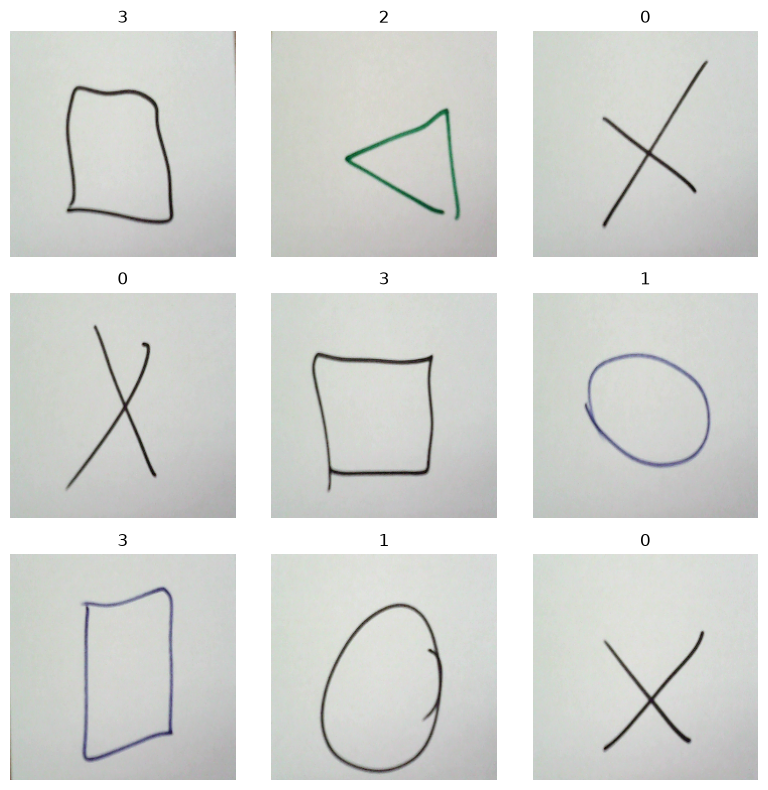

In [7]:
# =============================================================================
# Preview training images
# =============================================================================
plt.figure(figsize=(8, 8))
for images, labels in train_dataset.take(1):
    for i in range(min(BATCH_SIZE, 9)):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_index = labels[i].numpy().argmax()
        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()

In [8]:
print('Number of training batches: %d' % tf.data.experimental.cardinality(train_dataset))
print('Number of validation batches: %d' % tf.data.experimental.cardinality(validation_dataset))

Number of training batches: 4
Number of validation batches: 1


In [9]:
# =============================================================================
# Prefetch datasets for performance
# =============================================================================
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

print('Number of testing batches: %d' % tf.data.experimental.cardinality(test_dataset))

Number of testing batches: 1


In [10]:
# =============================================================================
# Data Augmentation
# =============================================================================
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(factor=0.2),   
])

"""
# =============================================================================
# Full Data Augmentation Pipeline
# =============================================================================
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),             # flip left/right
    layers.RandomRotation(0.1),                  # rotate ±10%
    layers.RandomZoom(0.1),                      # zoom in/out
    layers.RandomTranslation(0.1, 0.1),          # shift X/Y
    layers.RandomBrightness(factor=0.1),         # color jitter (TF 2.15+)
    layers.RandomContrast(0.1),                  # adjust contrast
    layers.RandomGaussianBlur(
        kernel_size=3,     # size of blur kernel (3, 5, etc.)
        sigma=(0.1, 2.0)   # range of possible blur intensity
    )  
])
"""

'\n# =============================================================================\n# Full Data Augmentation Pipeline\n# =============================================================================\ndata_augmentation = tf.keras.Sequential([\n    layers.RandomFlip("horizontal"),             # flip left/right\n    layers.RandomRotation(0.1),                  # rotate ±10%\n    layers.RandomZoom(0.1),                      # zoom in/out\n    layers.RandomTranslation(0.1, 0.1),          # shift X/Y\n    layers.RandomBrightness(factor=0.1),         # color jitter (TF 2.15+)\n    layers.RandomContrast(0.1),                  # adjust contrast\n    layers.RandomGaussianBlur(\n        kernel_size=3,     # size of blur kernel (3, 5, etc.)\n        sigma=(0.1, 2.0)   # range of possible blur intensity\n    )  \n])\n'

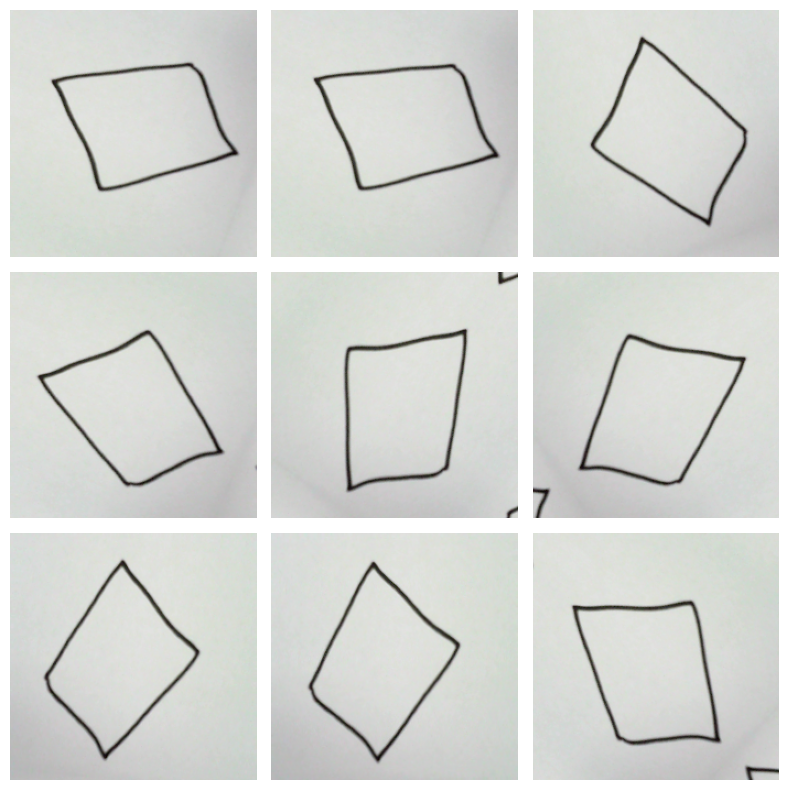

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for first_image, _ in train_dataset.unbatch().take(1):
    for ax in axes.flat:
        augmented = data_augmentation(
            tf.expand_dims(first_image, axis=0),
            training=True,
        )
        ax.imshow((augmented[0] / 255).numpy())
        ax.axis("off")

plt.tight_layout()

In [12]:
# AUTOTUNE
# =============================================================================
# TensorBoard Logging
# =============================================================================
log_dir = "logs/fit"
tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=log_dir,
    histogram_freq=1
)

# Starten in Shell: tensorboard --logdir logs/fit

In [13]:
# =============================================================================
# MobileNetV2 (Transfer Learning)
# =============================================================================
base_model = tf.keras.applications.MobileNetV2(
#base_model = tf.keras.applications.MobileNetV3Large(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

# Let's take a look at the base model architecture
#base_model.summary()

In [14]:
# Build a model by chaining together the data augmentation, rescaling, base_model and feature extractor layers
inputs = keras.Input(shape=IMG_SIZE + (3,))

x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x) # best
#x = tf.keras.applications.mobilenet_v3.preprocess_input(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

In [15]:
model.compile(
    optimizer=keras.optimizers.Adam(LR_SCHEDULER),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
# =============================================================================
# Early stopping after e.g. 10 epochs if loss does not improve
# =============================================================================
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

In [17]:
# =============================================================================
# Callback for training
# =============================================================================
from datetime import datetime
from pathlib import Path

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
checkpoint_dir = Path(checkpoint_filepath)
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_file = checkpoint_dir / f"chpt_{timestamp}.keras"

print(checkpoint_file)  # Should end with chpt_YYYYMMDD_HHMMSS.keras

# Set verbose flag to 0 to omit loss/accuracy output per epoch
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_file),
    monitor='val_loss',       # metric to monitor
    save_best_only=True,      # only save when metric improves
    mode='auto',              # minimize loss and aximize accuracy
    verbose=0,                # Print a line when the model is saved
)

/home/pi/ml_project/datasets/symbols/chpt/chpt_20261120_082157.keras


In [18]:
# =============================================================================
# Training (Feature Extraction)
# =============================================================================
initial_epochs = 10 # best: 50

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=initial_epochs,
    shuffle=True,
    callbacks=[checkpoint,
               early_stopping,
               tensorboard_callback],
)

# Starten in Shell: tensorboard --logdir logs/fit

Epoch 1/10


/home/pi/ml_project/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


4/4 ━━━━━━━━━━━━━━━━━━━━ 26s 6s/step - accuracy: 0.2149 - loss: 1.7106 - val_accuracy: 0.5000 - val_loss: 1.1814
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 5s/step - accuracy: 0.5620 - loss: 1.0406 - val_accuracy: 0.7500 - val_loss: 0.7412
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 17s 5s/step - accuracy: 0.8017 - loss: 0.6557 - val_accuracy: 0.8333 - val_loss: 0.5025
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 5s/step - accuracy: 0.8843 - loss: 0.4482 - val_accuracy: 0.8750 - val_loss: 0.3759
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 17s 5s/step - accuracy: 0.9339 - loss: 0.2928 - val_accuracy: 0.9583 - val_loss: 0.2987
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 5s/step - accuracy: 0.9752 - loss: 0.2057 - val_accuracy: 0.9583 - val_loss: 0.2400
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 5s/step - accuracy: 0.9669 - loss: 0.1702 - val_accuracy: 0.9583 - val_loss: 0.2018
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 20s 5s/step - accuracy: 0.9917 - loss: 0.1448 - val_accuracy: 1.0000 - val_loss: 0.1717
Epoch 9/10
4/4 ━━━━

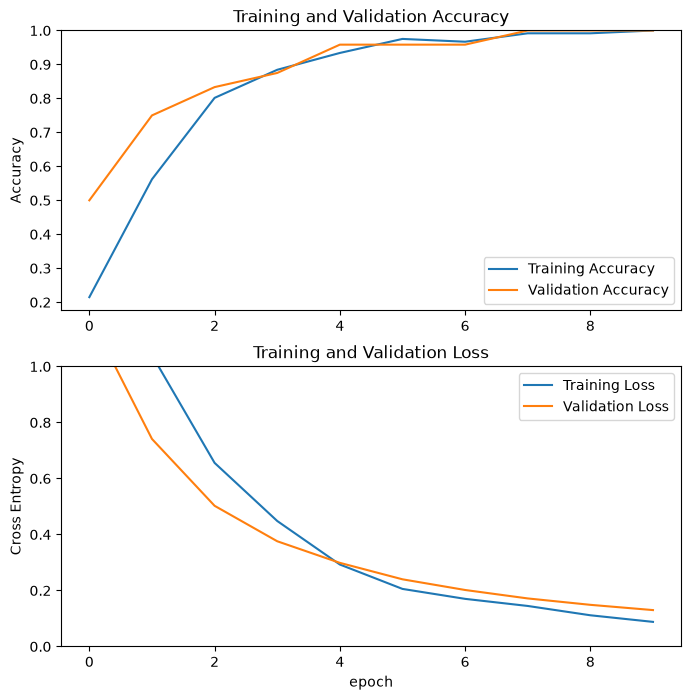

In [19]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [20]:
# =============================================================================
# Fine Tuning
# =============================================================================
# Let's take a look to see how many layers are in the base model
print("Number of layers in the base model: ", len(base_model.layers))

base_model.trainable = True

# Fine-tune from this layer onwards
fine_tune_from = 100

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.RMSprop(LR_SCHEDULER_FINE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_epochs = 10 # best: 100
total_epochs = initial_epochs + fine_tune_epochs

history_fine = model.fit(train_dataset,
                         validation_data=validation_dataset,
                         epochs=total_epochs,
                         initial_epoch=len(history.epoch),
                         shuffle=True,
                         callbacks=[checkpoint,
                                    early_stopping,
                                    tensorboard_callback],
)

Number of layers in the base model:  154
Epoch 11/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 39s 7s/step - accuracy: 0.8926 - loss: 0.2835 - val_accuracy: 0.9583 - val_loss: 0.0886
Epoch 12/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 38s 6s/step - accuracy: 1.0000 - loss: 0.0403 - val_accuracy: 1.0000 - val_loss: 0.0639
Epoch 13/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 24s 6s/step - accuracy: 0.9752 - loss: 0.0586 - val_accuracy: 0.9583 - val_loss: 0.0678
Epoch 14/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 24s 6s/step - accuracy: 0.9917 - loss: 0.0243 - val_accuracy: 1.0000 - val_loss: 0.0554
Epoch 15/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 25s 6s/step - accuracy: 1.0000 - loss: 0.0161 - val_accuracy: 1.0000 - val_loss: 0.0466
Epoch 16/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 24s 6s/step - accuracy: 1.0000 - loss: 0.0081 - val_accuracy: 1.0000 - val_loss: 0.0399
Epoch 17/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 24s 7s/step - accuracy: 1.0000 - loss: 0.0060 - val_accuracy: 1.0000 - val_loss: 0.0367
Epoch 18/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 24s 6s/step - accuracy: 1.0000 - loss: 0.0034 -

In [21]:
acc += history_fine.history['accuracy']
val_acc += history_fine.history['val_accuracy']

loss += history_fine.history['loss']
val_loss += history_fine.history['val_loss']

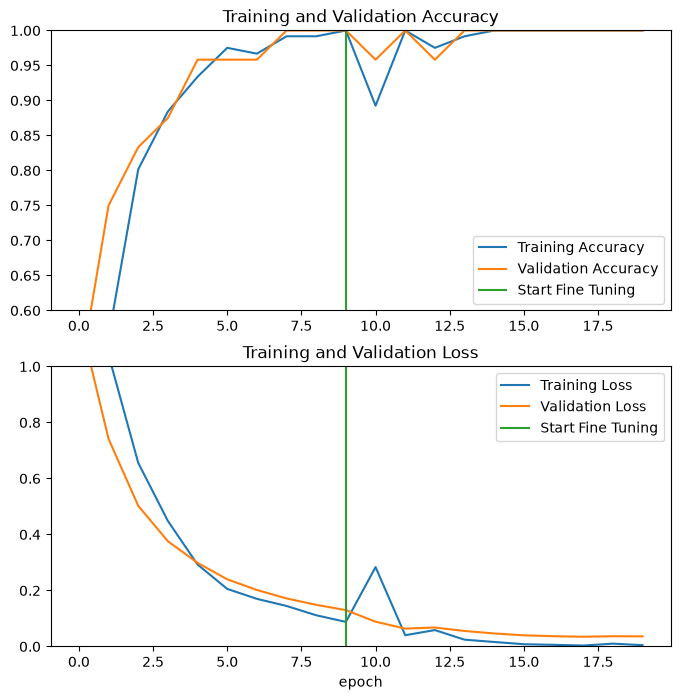

In [22]:
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.ylim([0.6, 1])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.ylim([0, 1.0])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [23]:
# =============================================================================
# Test Accuracy on test set
# =============================================================================
results = model.evaluate(test_dataset, 
                         verbose=1, 
                         return_dict=True,
                         )

loss = results["loss"]
accuracy = results.get("accuracy")  # available if you compiled with an accuracy metric

print("Test loss:", loss)
print("Test accuracy:", accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 1.0000 - loss: 0.0658
Test loss: 0.06576118618249893
Test accuracy: 1.0


E0000 00:00:1795159784.219738  123008 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Klassen: ['0', '1', '2', '3']


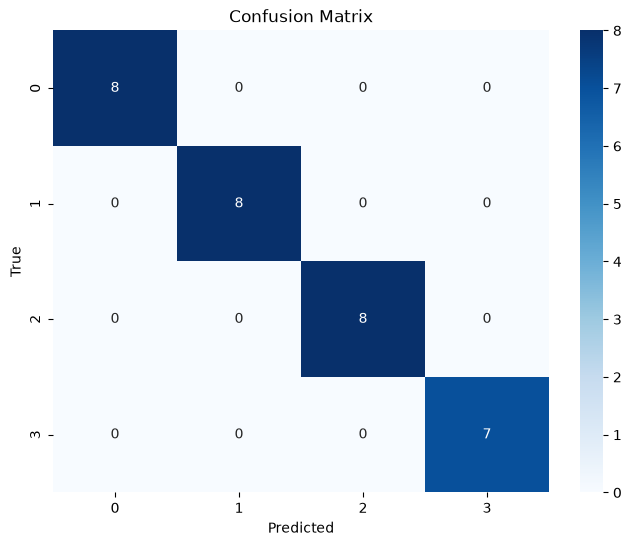


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         8
           3       1.00      1.00      1.00         7

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



In [24]:
# =============================================================================
# Konfusionsmatrix + Klassifizierungsreport
# =============================================================================
# Daten aus Validation/Test holen
y_true = []
y_pred = []

for images, labels in test_dataset:
    preds = model.predict(images)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Klassenliste
print("Klassen:", class_names)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

In [25]:
loss, accuracy = model.evaluate(test_dataset)
print('Test accuracy :', accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 1.0000 - loss: 0.0658
Test accuracy : 1.0


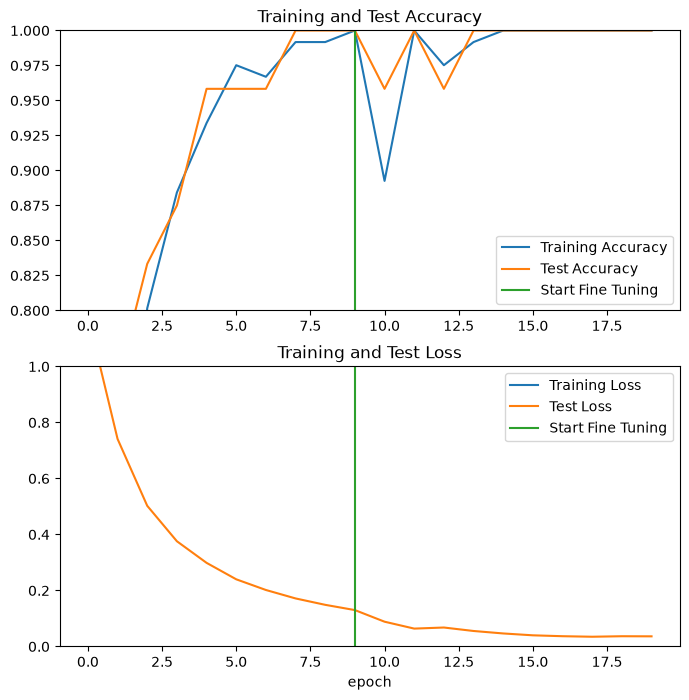

In [26]:
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Test Accuracy')
plt.ylim([0.8, 1])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('Training and Test Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Test Loss')
plt.ylim([0, 1.0])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Test Loss')
plt.xlabel('epoch')
plt.show()

Grad-CAM layer: block_6_expand (None, 28, 28, 192)


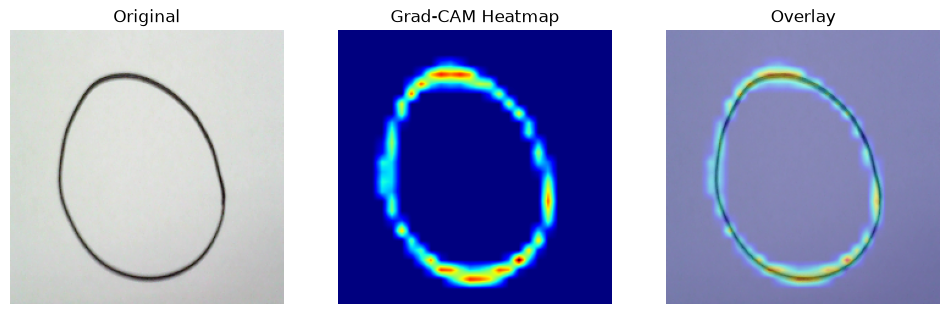

Predicted class: 1
Prediction: [[1.3032496e-07 9.9998617e-01 1.1254226e-06 1.2532632e-05]]
Prediction: 0.9999862


In [33]:
# =============================================================================
# Grad-CAM Visualisierung
# =============================================================================

# ============================================================
# 1. Select a higher-resolution convolution in MobileNetV2
# ============================================================
backbone = base_model

# The final Conv_1 map is only 7x7 for 224x224 inputs. This earlier
# feature map is 28x28 and gives Grad-CAM finer spatial localization.
last_conv = backbone.get_layer("block_6_expand")

print("Grad-CAM layer:", last_conv.name, last_conv.output.shape)


# ============================================================
# 2. Create a Grad-CAM model for the nested backbone
# ============================================================
grad_model = tf.keras.models.Model(
    inputs=backbone.input,
    outputs=[last_conv.output, backbone.output],
)

# Reuse the classifier head already trained on top of MobileNetV2.
pooling_layer = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D)
)
dropout_layer = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Dropout)
)
classifier_layer = next(
    layer for layer in reversed(model.layers)
    if isinstance(layer, tf.keras.layers.Dense)
)


# ============================================================
# 3. Extract one validation image
# ============================================================
example_img, _ = next(iter(validation_dataset))
example_img = example_img[0].numpy()

# Match the model's inference path: augmentation is inactive and MobileNetV2
# preprocessing maps raw 0-255 values to the backbone's expected range.
if example_img.max() <= 1.0:
    example_img = example_img * 255.0

input_image = np.expand_dims(example_img, 0)
input_backbone = tf.keras.applications.mobilenet_v2.preprocess_input(
    input_image.copy()
)


# ============================================================
# 4. Find the predicted class and calculate Grad-CAM
# ============================================================
with tf.GradientTape() as tape:
    conv_outputs, backbone_features = grad_model(
        input_backbone, training=False
    )
    x = pooling_layer(backbone_features)
    x = dropout_layer(x, training=False)
    predictions = classifier_layer(x)
    pred_index_tensor = tf.argmax(predictions[0])
    score = tf.gather(predictions[0], pred_index_tensor)

pred_index = int(pred_index_tensor.numpy())

grads = tape.gradient(score, conv_outputs)
if grads is None:
    raise RuntimeError("Grad-CAM received no gradients; check last_conv")

pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
heatmap = tf.reduce_sum(conv_outputs[0] * pooled_grads, axis=-1)
heatmap = tf.maximum(heatmap, 0)
heatmap /= tf.reduce_max(heatmap) + 1e-8
heatmap = heatmap.numpy()


# ============================================================
# 5. Resize and visualize
# ============================================================
img_uint8 = example_img.astype("uint8")

heatmap_resized = cv2.resize(
    heatmap,
    (img_uint8.shape[1], img_uint8.shape[0]),
)
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)

img_bgr = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2BGR)
overlay_bgr = cv2.addWeighted(img_bgr, 0.6, heatmap_color, 0.4, 0)
overlay = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.title("Original")
plt.imshow(img_uint8)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Grad-CAM Heatmap")
plt.imshow(heatmap_resized, cmap="jet")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Overlay")
plt.imshow(overlay)
plt.axis("off")

plt.show()

print("Predicted class:", class_names[pred_index])
print("Prediction:", predictions.numpy())
print("Prediction:", predictions.numpy()[0, pred_index])

In [28]:
# =============================================================================
# Modell speichern
# =============================================================================
keras.saving.save_model(model, "model.keras")

print("Modelle gespeichert: model.keras")

# =============================================================================
# Modell laden
# =============================================================================
loaded_model = keras.models.load_model("model.keras")

print("Modelle erfolgreich geladen!")

Modelle gespeichert: model.keras
Modelle erfolgreich geladen!
